# 03 — DistilBERT Toxicity Classification

## Toxicity Classification and Fairness in Online Moderation

This notebook implements a more advanced supervised binary toxicity classification model using DistilBERT, a pretrained transformer-based language model developed by Hugging Face. Unlike our baseline TF-IDF logistic regression classifier, DistilBERT uses contextual word representations to better capture the meaning and relationships between words in online comments.

Using the cleaned Civil Comments dataset prepared in `01_data_preparation.ipynb`, we will fine-tune DistilBERT to classify comments as toxic or non-toxic. We will use stratified sampling to reduce computational costs, address class imbalance through class weighting, and optimize the classification threshold using validation data. We will then evaluate the final model on an independent test set and save the trained model and its predictions. These outputs will be used in separate notebooks for model comparison, demographic fairness analysis, and the interactive application.

Objectives:
1. Load the cleaned Civil Comments dataset with binary toxicity labels
2. Load the pretrained DistilBERT tokenizer and model
3. Tokenize comment text and prepare inputs for transformer-based classification, documenting preprocessing choices and maximum sequence length
4. Fine-tune DistilBERT on a stratified training sample, accounting for class imbalance and computational constraints
5. Examine the relationship between training sample size, computational cost, and validation F1-score
6. Evaluate model performance on the validation set using accuracy, precision, recall, F1-score, and PR-AUC
7. Optimize the classification decision threshold using validation predictions to improve F1-score without introducing test leakage
8. Examine confusion matrices and evaluate false-positive and false-negative predictions
9. Evaluate the final model on the independent test set using the selected classification threshold
10. Save the trained model, tokenizer, evaluation metrics, and classification threshold for reproducibility
11. Generate and save predicted toxicity probabilities and binary classifications for the **test set**, using the same output structure as our TF-IDF logistic regression classifier

### Import necessary packages - load processed dataset

In [70]:
from pathlib import Path
import json
import time
import random

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from datasets import load_from_disk
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

DATA_DIR = Path("civil_comments_processed")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
ds = load_from_disk(str(DATA_DIR))
print(ds)
for split in ("train", "validation", "test"):
    assert split in ds, f"Missing split: {split}"
    assert {"text", "label"}.issubset(ds[split].column_names), f"Missing required columns in {split}"
    assert set(ds[split].unique("label")).issubset({0, 1}), f"Labels in {split} must be binary"
print("Training columns:", ds["train"].column_names)

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
        num_rows: 1778797
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
        num_rows: 96255
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label'],
        num_rows: 96862
    })
})
Training columns: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit', 'label']


### Pipeline inputs

In [73]:
MODEL_NAME = "distilbert-base-uncased"
NUM_LABELS = 2
MAX_LENGTH = 256
LEARNING_RATE = 2e-5
BATCH_SIZE = 16
NUM_EPOCHS = 2
RANDOM_SEED = 42
TRAIN_SIZE = 50_000  # set to 100_000 or 200_000 for a deliberate comparison
VAL_SIZE = 10_000    # fixed stratified validation subset for efficient comparisons
USE_CLASS_WEIGHTS = False  # optional experiment; compare validation F1/PR-AUC before enabling

EXPERIMENT_NAME = f"distilbert_{TRAIN_SIZE // 1000}k" + ("_weighted" if USE_CLASS_WEIGHTS else "")
CHECKPOINT_DIR = RESULTS_DIR / f"{EXPERIMENT_NAME}_checkpoints"
MODEL_DIR = RESULTS_DIR / f"{EXPERIMENT_NAME}_model"

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
print("Device:", "cuda" if torch.cuda.is_available() else "mps" if hasattr(torch.backends, "mps") and torch.backends.mps.is_available() else "cpu")

Device: mps


### Stratified training and validation samples

In [76]:
'''return a reproducible subset retaining the original binary class proportions'''
def stratified_sample(split, size, seed=RANDOM_SEED):
    if size is None or size >= len(split):
        return split
    encoded = split.class_encode_column("label")
    return encoded.train_test_split(train_size=size, stratify_by_column="label", seed=seed)["train"]

train_subset = stratified_sample(ds["train"], TRAIN_SIZE)
val_subset = stratified_sample(ds["validation"], VAL_SIZE)
print("Training subset:", len(train_subset), "Validation subset:", len(val_subset))

# show the actual class imbalance instead of assuming a particular ratio.
counts = pd.Series(train_subset["label"]).value_counts().reindex([0, 1], fill_value=0)
class_distribution = pd.DataFrame({"Count": counts, "Percentage": counts / counts.sum() * 100})
class_distribution.index = ["Non-Toxic", "Toxic"]
display(class_distribution.round(2))

Training subset: 50000 Validation subset: 10000


,Count,Percentage
Non-Toxic,46000,92.0
Toxic,4000,8.0


### Tokenization on sample from dataset
DistilBERT uses its pretrained uncased tokenizer. We do not manually lowercase, remove punctuation, or strip stop words: those transformations could change context or interfere with pretrained tokenization. Texts exceeding MAX_LENGTH=256 are truncated and shorter texts are padded dynamically within each batch.

In [80]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=MAX_LENGTH)

def tokenize_split(split):
    # keep only labels and model inputs; preserve raw text in ds for later exports
    tokenized = split.map(tokenize_function, batched=True,
                          remove_columns=[col for col in split.column_names if col != "label"])
    if "token_type_ids" in tokenized.column_names:
        tokenized = tokenized.remove_columns("token_type_ids")
    return tokenized

train_tokenized = tokenize_split(train_subset)
val_tokenized = tokenize_split(val_subset)
print(train_tokenized)
print(val_tokenized)
print("First tokenized example:", train_tokenized[0])

Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 50000
})
Dataset({
    features: ['label', 'input_ids', 'attention_mask'],
    num_rows: 10000
})
First tokenized example: {'label': 1, 'input_ids': [101, 2515, 3011, 3178, 2031, 3643, 1999, 1996, 2287, 1997, 4785, 2689, 7087, 10231, 3658, 1998, 4167, 8871, 8351, 1029, 2053, 2009, 2515, 2025, 1010, 2009, 2001, 1998, 2003, 1037, 8257, 2013, 2049, 2200, 2927, 999, 2045, 2003, 2145, 2053, 6947, 1010, 2025, 2028, 2065, 16042, 6351, 2003, 10808, 2256, 4785, 1010, 2498, 999, 16770, 1024, 1013, 1013, 7479, 1012, 7858, 1012, 4012, 1013, 3422, 1029, 1058, 1027, 25353, 6784, 25708, 2278, 12273, 1011, 1047, 16770, 1024, 1013, 1013, 7479, 1012, 7858, 1012, 4012, 1013, 3422, 1029, 1058, 1027, 25353, 6784, 25708, 2278, 12273, 1011, 1047, 16770, 1024, 1013, 1013, 7479, 1012, 7858, 1012, 4012, 1013, 3422, 1029, 1058, 1027, 2006, 1035, 1051, 6038, 2595, 2487, 2094, 2620, 2860, 1998, 1996, 2862, 1997, 2107, 3632, 2006, 1998,

### Training Sample Size Selection

During preliminary experimentation, we evaluated the effect of training sample size on DistilBERT's classification performance. We compared models trained on stratified samples of 50,000 and 200,000 comments, evaluating both on the validation set.

| Training Sample Size | Validation F1 |
|---|---|
| 50,000 | 0.669 |
| 200,000 | 0.684 |

Increasing the training sample size fourfold improved validation F1 by only 0.015 (1.5 percentage points), while training on 200,000 comments required over an hour.

Given the relatively small performance improvement and substantial computational cost, we selected **50,000 training examples** as our default configuration. This allows us to prioritize computational efficiency while maintaining competitive classification performance.

### Model initialization
The default uses standard cross-entropy with stratified sampling, which preserves class imbalance rather than correcting it. To explicitly address imbalance, set USE_CLASS_WEIGHTS=True: inverse-frequency weights are computed only from the sampled training labels, and used in cross-entropy loss. Compare weighted and unweighted models using validation F1 and PR-AUC; weighting may improve minority recall while hurting precision. Do not additionally oversample without a separate controlled experiment.

In [84]:
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=NUM_LABELS)

# compute inverse-frequency class weights only from the training sample.
train_counts = np.bincount(np.asarray(train_subset["label"], dtype=int), minlength=NUM_LABELS)
assert np.all(train_counts > 0), "Both classes must occur in the training sample."
class_weights = len(train_subset) / (NUM_LABELS * train_counts)
print("Class weights [non-toxic, toxic]:", class_weights)

class WeightedTrainer(Trainer):
    '''optional class-weighted cross-entropy for binary classification'''
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(**inputs)
        weights = torch.tensor(class_weights, dtype=outputs.logits.dtype, device=outputs.logits.device)
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels, weight=weights)
        return (loss, outputs) if return_outputs else loss

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Class weights [non-toxic, toxic]: [0.54347826 6.25      ]


### Fine-tune and return best results from validation

In [87]:
training_args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    num_train_epochs=NUM_EPOCHS,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    save_total_limit=2,
    logging_steps=100,
    seed=RANDOM_SEED,
    report_to="none",
    dataloader_pin_memory=False,
)

trainer_class = WeightedTrainer if USE_CLASS_WEIGHTS else Trainer
trainer = trainer_class(
    model=model,
    args=training_args,
    train_dataset=train_tokenized,
    eval_dataset=val_tokenized,
    processing_class=tokenizer,
    data_collator=DataCollatorWithPadding(tokenizer),
)

start_time = time.time()
trainer.train()
training_time_min = (time.time() - start_time) / 60
print(f"Training completed in {training_time_min:.2f} minutes")
print("Best checkpoint:", trainer.state.best_model_checkpoint)

Epoch,Training Loss,Validation Loss
1,0.138520,0.140208
2,0.098034,0.167538


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed in 20.61 minutes
Best checkpoint: results/distilbert_50k_checkpoints/checkpoint-3125


### Tune decision threshold on validation set
See which decision threshold produces the highest validation F1.

In [94]:
def positive_probabilities(logits):
    # numerically stable softmax; index 1 corresponds to the toxic class
    return torch.softmax(torch.as_tensor(logits), dim=1)[:, 1].numpy()

def evaluate_at_threshold(y_true, probabilities, threshold):
    predicted = (probabilities >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, predicted),
        "Precision": precision_score(y_true, predicted, zero_division=0),
        "Recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "PR-AUC": average_precision_score(y_true, probabilities),
    }

val_outputs = trainer.predict(val_tokenized)
val_labels = np.asarray(val_outputs.label_ids)
val_probabilities = positive_probabilities(val_outputs.predictions)
threshold_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
threshold_results = pd.DataFrame([
    {"Threshold": float(t), **evaluate_at_threshold(val_labels, val_probabilities, t)}
    for t in threshold_grid
])
BEST_THRESHOLD = float(threshold_results.sort_values(["F1", "Threshold"], ascending=[False, True]).iloc[0]["Threshold"])
print("Selected validation threshold:", BEST_THRESHOLD)
display(threshold_results.sort_values("F1", ascending=False).head(10).round(4))
threshold_results.to_csv(RESULTS_DIR / f"{EXPERIMENT_NAME}_threshold_search.csv", index=False)

Selected validation threshold: 0.32


,Threshold,Accuracy,Precision,Recall,F1,PR-AUC
27,0.32,0.9487,0.6841,0.6485,0.6658,0.7404
30,0.35,0.9496,0.6972,0.6371,0.6658,0.7404
21,0.26,0.9468,0.6596,0.6713,0.6654,0.7404
20,0.25,0.9463,0.6544,0.6751,0.6646,0.7404
26,0.31,0.9482,0.6786,0.6510,0.6645,0.7404
28,0.33,0.9488,0.6875,0.6421,0.6640,0.7404
25,0.30,0.9478,0.6745,0.6523,0.6632,0.7404
29,0.34,0.9488,0.6885,0.6396,0.6632,0.7404
19,0.24,0.9456,0.6481,0.6777,0.6625,0.7404
22,0.27,0.9467,0.6612,0.6637,0.6624,0.7404


### Validation metrics and confussion matrix

,Model,Training Rows,Validation Rows,Epochs,Threshold,Accuracy,Precision,Recall,F1,PR-AUC,Training Time (min),Learning Rate,Batch Size,Max Length,Class Weighted,Random Seed
0,DistilBERT,50000,10000,2,0.32,0.9487,0.6841,0.6485,0.6658,0.7404,20.61,0.0,16,256,False,42


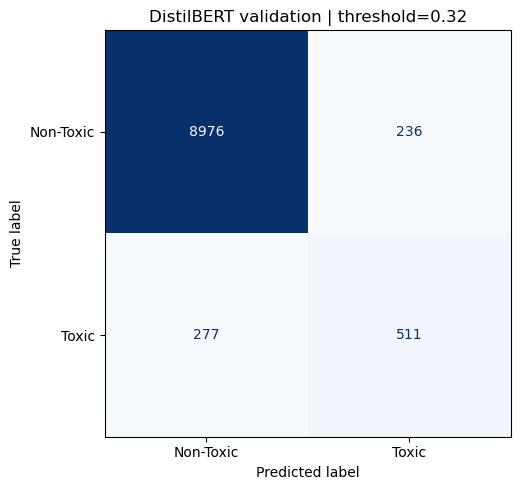

In [97]:
val_metrics = evaluate_at_threshold(val_labels, val_probabilities, BEST_THRESHOLD)
experiment_results = {
    "Model": "DistilBERT", "Training Rows": len(train_subset),
    "Validation Rows": len(val_subset), "Epochs": NUM_EPOCHS,
    "Threshold": BEST_THRESHOLD, **val_metrics,
    "Training Time (min)": round(training_time_min, 2),
    "Learning Rate": LEARNING_RATE, "Batch Size": BATCH_SIZE,
    "Max Length": MAX_LENGTH, "Class Weighted": USE_CLASS_WEIGHTS,
    "Random Seed": RANDOM_SEED,
}
results_df = pd.DataFrame([experiment_results])
display(results_df.round(4))
results_df.to_csv(RESULTS_DIR / f"{EXPERIMENT_NAME}_validation_results.csv", index=False)

def plot_confusion(y_true, probabilities, threshold, title, output_file):
    predicted = (probabilities >= threshold).astype(int)
    cm = confusion_matrix(y_true, predicted, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay(cm, display_labels=["Non-Toxic", "Toxic"]).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"{title} | threshold={threshold:.2f}")
    plt.tight_layout()
    fig.savefig(output_file, dpi=300, bbox_inches="tight")
    plt.show()

plot_confusion(val_labels, val_probabilities, BEST_THRESHOLD, "DistilBERT validation",
               RESULTS_DIR / f"{EXPERIMENT_NAME}_validation_confusion_matrix.png")

### Test set performance

,Model,Split,Threshold,Accuracy,Precision,Recall,F1,PR-AUC
0,DistilBERT,test,0.32,0.9475,0.6818,0.6427,0.6617,0.7291


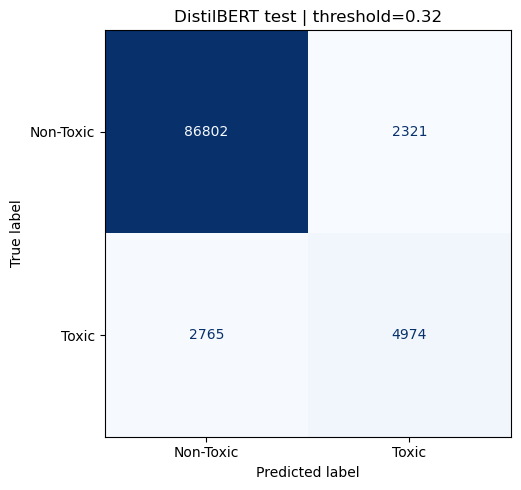

In [100]:
test_tokenized = tokenize_split(ds["test"])
test_outputs = trainer.predict(test_tokenized)
test_labels = np.asarray(test_outputs.label_ids)
test_probabilities = positive_probabilities(test_outputs.predictions)
test_metrics = evaluate_at_threshold(test_labels, test_probabilities, BEST_THRESHOLD)
test_results_df = pd.DataFrame([{"Model": "DistilBERT", "Split": "test",
                                 "Threshold": BEST_THRESHOLD, **test_metrics}])
display(test_results_df.round(4))
test_results_df.to_csv(RESULTS_DIR / f"{EXPERIMENT_NAME}_test_results.csv", index=False)
plot_confusion(test_labels, test_probabilities, BEST_THRESHOLD, "DistilBERT test",
               RESULTS_DIR / f"{EXPERIMENT_NAME}_test_confusion_matrix.png")

### Save pipeline configuration

In [103]:
# save the selected model and tokenizer
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))
settings = {
    "base_model": MODEL_NAME, "training_rows": len(train_subset),
    "validation_rows": len(val_subset), "max_length": MAX_LENGTH,
    "threshold": BEST_THRESHOLD, "class_weighted": USE_CLASS_WEIGHTS,
    "learning_rate": LEARNING_RATE, "epochs": NUM_EPOCHS,
    "seed": RANDOM_SEED, "training_minutes": training_time_min,
    "deduplication": "performed upstream in 01_data_preparation.ipynb; verify before use",
    "lowercasing": "distilbert-base-uncased tokenizer; raw text preserved",
}
(MODEL_DIR / "inference_settings.json").write_text(json.dumps(settings, indent=2))
print("Saved model:", MODEL_DIR.resolve())

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model: /Users/toddrosenbaum/Desktop/COSC 72/Final Project/results/distilbert_50k_model


### Save predictions for test set

In [109]:
# save DistilBERT test predictions for later analysis
predictions_df = pd.DataFrame({
    "text": ds["test"]["text"],
    "label": test_labels,
    "distilbert_probability": test_probabilities,
    "distilbert_prediction": (
        test_probabilities >= BEST_THRESHOLD
    ).astype(int)
})

# save predictions to CSV
predictions_path = RESULTS_DIR / "distilbert_test_predictions.csv"
predictions_df.to_csv(predictions_path, index=False)

# confirm saved results
print(f"Saved {len(predictions_df):,} test predictions")
print(f"File: {predictions_path.resolve()}")

# preview results
predictions_df.head()

Saved 96,862 test predictions
File: /Users/toddrosenbaum/Desktop/COSC 72/Final Project/results/distilbert_test_predictions.csv


,text,label,distilbert_probability,distilbert_prediction
0,[ Integrity means that you pay your debts.]\n\...,0,0.001926,0
1,This is malfeasance by the Administrator and t...,0,0.008311,0
2,@Rmiller101 - Spoken like a true elitist. But ...,0,0.029269,0
3,"Paul: Thank you for your kind words. I do, in...",0,0.019603,0
4,Sorry you missed high school. Eisenhower sent ...,0,0.004353,0
